<a href="https://colab.research.google.com/github/mdzubayereashraf/Ostad-AI-Engineering-Course-Assignments/blob/main/Assignmen_No_18(Sentiment_Analysis_on_Product_Reviews_(IMDB)_%7C%7C_Customer_Segmentation_Analysis).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Import Libraries and Load Dataset**

In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np

imdb = load_dataset("stanfordnlp/imdb")

print(imdb)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


## **Dataset Exploration (EDA)**

In [4]:
# Check dataset structure
print("Training samples:", len(imdb["train"]))
print("Testing samples:", len(imdb["test"]))

# Check sentiment labels
print("\nLabel distribution:")
print(pd.Series(imdb["train"]["label"]).value_counts())

# Display sentiment meaning
print("\nLabel meanings:")
print("0 = Negative")
print("1 = Positive")

Training samples: 25000
Testing samples: 25000

Label distribution:
0    12500
1    12500
Name: count, dtype: int64

Label meanings:
0 = Negative
1 = Positive


In [5]:
# Display a negative review
print("NEGATIVE REVIEW:\n")
print(imdb["train"][0]["text"])

print("\nSentiment:", imdb["train"][0]["label"])

# Display a positive review
print("\n" + "=" * 80)

print("\nPOSITIVE REVIEW:\n")
print(imdb["train"][1]["text"])

print("\nSentiment:", imdb["train"][1]["label"])

NEGATIVE REVIEW:

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few an

## **Create a Cleaning Function**

In [6]:
import re
import string

def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

## **Test the Cleaning Function**

In [7]:
sample_review = imdb["train"][0]["text"]

cleaned_review = clean_text(sample_review)

print("Original Review:\n")
print(sample_review[:500])

print("\n" + "=" * 80)

print("\nCleaned Review:\n")
print(cleaned_review[:500])

Original Review:

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent


Cleaned Review:

i rented i am curiousyellow from my video store because of all the controversy that surrounded it when it was first released in 1967 i also heard that at first it was seized by us customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life in particular she wants t

## **Prepare Training and Testing Data**

In [27]:

import numpy as np
from sklearn.model_selection import train_test_split

# Extract original training data
X_train_text = imdb["train"]["text"]
y_train_original = np.array(imdb["train"]["label"])

# Extract official testing data
X_test_text = imdb["test"]["text"]
y_test = np.array(imdb["test"]["label"])

# Apply text cleaning
X_train_clean = [clean_text(text) for text in X_train_text]
X_test_clean = [clean_text(text) for text in X_test_text]

# Split training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_clean,
    y_train_original,
    test_size=0.20,
    random_state=42,
    stratify=y_train_original
)

# Keep official test data separate
X_test = X_test_clean

print("Training reviews:", len(X_train))
print("Training labels:", len(y_train))

print("Validation reviews:", len(X_val))
print("Validation labels:", len(y_val))

print("Testing reviews:", len(X_test))
print("Testing labels:", len(y_test))


Training reviews: 20000
Training labels: 20000
Validation reviews: 5000
Validation labels: 5000
Testing reviews: 25000
Testing labels: 25000


## **Train-Validation Split**

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train_split, y_val = train_test_split(
    X_train_clean,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test_clean))

Training samples: 20000
Validation samples: 5000
Testing samples: 25000


## **TF-IDF Vectorization**

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

## **Transform the Reviews**

In [11]:
# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test_clean)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (20000, 30000)
Validation TF-IDF shape: (5000, 30000)
Testing TF-IDF shape: (25000, 30000)


## **Train Logistic Regression Model**

In [12]:
from sklearn.linear_model import LogisticRegression

tfidf_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
tfidf_model.fit(X_train_tfidf, y_train_split)

print("TF-IDF Logistic Regression training completed!")

TF-IDF Logistic Regression training completed!


## **Calculate Evaluation Metrics**

In [13]:
# Predict validation data
y_val_pred = tfidf_model.predict(X_val_tfidf)

print("Predictions generated successfully!")

Predictions generated successfully!


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate metrics
tfidf_accuracy = accuracy_score(y_val, y_val_pred)
tfidf_precision = precision_score(y_val, y_val_pred)
tfidf_recall = recall_score(y_val, y_val_pred)
tfidf_f1 = f1_score(y_val, y_val_pred)

print("TF-IDF Model - Validation Results")
print("-" * 40)

print(f"Accuracy:  {tfidf_accuracy:.4f}")
print(f"Precision: {tfidf_precision:.4f}")
print(f"Recall:    {tfidf_recall:.4f}")
print(f"F1-score:  {tfidf_f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Negative", "Positive"]
))

TF-IDF Model - Validation Results
----------------------------------------
Accuracy:  0.8996
Precision: 0.8936
Recall:    0.9072
F1-score:  0.9004

Classification Report:

              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      2500
    Positive       0.89      0.91      0.90      2500

    accuracy                           0.90      5000
   macro avg       0.90      0.90      0.90      5000
weighted avg       0.90      0.90      0.90      5000



In [44]:

import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Measure TF-IDF classifier training time
start_time = time.time()

tfidf_model.fit(X_train_tfidf, y_train_split)

tfidf_time = time.time() - start_time

# Predict official test data
tfidf_predictions = tfidf_model.predict(X_test_tfidf)

# Evaluate test performance
print("TF-IDF Test Results")
print("-------------------------")

print("Accuracy:",
      accuracy_score(y_test, tfidf_predictions))

print("Precision:",
      precision_score(y_test, tfidf_predictions))

print("Recall:",
      recall_score(y_test, tfidf_predictions))

print("F1 Score:",
      f1_score(y_test, tfidf_predictions))

print("Training Time:",
      round(tfidf_time, 2), "seconds")


TF-IDF Test Results
-------------------------
Accuracy: 0.89536
Precision: 0.8902400505369551
Recall: 0.90192
F1 Score: 0.8960419647114926
Training Time: 3.16 seconds


## **Confusion Matrix**

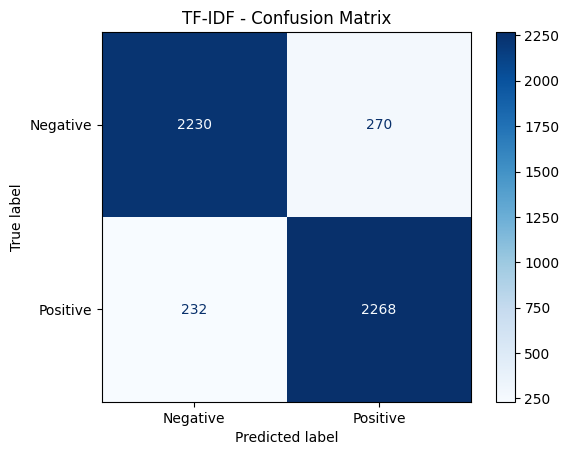

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("TF-IDF - Confusion Matrix")
plt.show()

## **Save the Results**

In [16]:
results = []

results.append({
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": tfidf_accuracy,
    "Precision": tfidf_precision,
    "Recall": tfidf_recall,
    "F1-score": tfidf_f1
})

pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1-score
0,TF-IDF + Logistic Regression,0.8996,0.893617,0.9072,0.900357


## **Install Gensim**

In [17]:
!pip install -q gensim

## **Import Libraries**

In [18]:
from gensim.models import Word2Vec
from nltk.tokenize import word_tokenize
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## **Tokenize the Reviews**

In [29]:
X_train_tokens = [text.split() for text in X_train]
X_val_tokens = [text.split() for text in X_val]
X_test_tokens = [text.split() for text in X_test]

## **Train Word2Vec**

In [20]:
w2v_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    seed=42,
    epochs=10
)

## **Convert Reviews into Vectors**

In [21]:
def document_vector(tokens, model):
    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if not vectors:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

## **Transform all datasets**

In [22]:
X_train_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_train_tokens
])

X_val_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_val_tokens
])

X_test_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_test_tokens
])

print("Training shape:", X_train_w2v.shape)
print("Validation shape:", X_val_w2v.shape)
print("Testing shape:", X_test_w2v.shape)

Training shape: (20000, 100)
Validation shape: (5000, 100)
Testing shape: (25000, 100)


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report
)
import time
import numpy as np

# Convert reviews into Word2Vec feature vectors
X_train_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_train_tokens
])

X_val_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_val_tokens
])

X_test_w2v = np.array([
    document_vector(tokens, w2v_model)
    for tokens in X_test_tokens
])

print("Training shape:", X_train_w2v.shape)
print("Validation shape:", X_val_w2v.shape)
print("Testing shape:", X_test_w2v.shape)

# Train classifier
start_time = time.time()

w2v_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

w2v_classifier.fit(X_train_w2v, y_train)

w2v_time = time.time() - start_time

# Predictions
w2v_predictions = w2v_classifier.predict(X_test_w2v)

print("\nWord2Vec Classification Report")
print(classification_report(y_test, w2v_predictions))

print("Word2Vec Accuracy:",
      accuracy_score(y_test, w2v_predictions))
print("Word2Vec Precision:",
      precision_score(y_test, w2v_predictions))
print("Word2Vec Recall:",
      recall_score(y_test, w2v_predictions))
print("Word2Vec F1 Score:",
      f1_score(y_test, w2v_predictions))
print("Training Time:", round(w2v_time, 2), "seconds")

Training shape: (20000, 100)
Validation shape: (5000, 100)
Testing shape: (25000, 100)

Word2Vec Classification Report
              precision    recall  f1-score   support

           0       0.85      0.86      0.85     12500
           1       0.86      0.84      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000

Word2Vec Accuracy: 0.8524
Word2Vec Precision: 0.8578391551584078
Word2Vec Recall: 0.8448
Word2Vec F1 Score: 0.8512696493349455
Training Time: 0.25 seconds


## **Implement BERT embeddings**

In [32]:
!pip install -q transformers accelerate

In [33]:
import torch
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import DataLoader, Dataset
import numpy as np
import time

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Load pretrained DistilBERT
bert_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)

bert_model = bert_model.to(device)
bert_model.eval()

print("DistilBERT loaded successfully!")

Using device: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT loaded successfully!


In [38]:
class ReviewDataset(Dataset):

    def __init__(self, texts):
        self.texts = texts

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


def get_bert_embeddings(texts):

    dataset = ReviewDataset(texts)

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False
    )

    embeddings = []

    with torch.no_grad():

        for batch in loader:

            inputs = tokenizer(
                list(batch),
                padding=True,
                truncation=True,
                max_length=256,
                return_tensors="pt"
            )

            inputs = {
                key: value.to(device)
                for key, value in inputs.items()
            }

            outputs = bert_model(**inputs)

            hidden = outputs.last_hidden_state

            mask = inputs["attention_mask"].unsqueeze(-1).float()

            pooled = (
                (hidden * mask).sum(dim=1)
                / mask.sum(dim=1).clamp(min=1e-9)
            )

            embeddings.append(pooled.cpu().numpy())

    return np.vstack(embeddings)

In [39]:
start_time = time.time()

X_train_bert = get_bert_embeddings(X_train)
X_val_bert = get_bert_embeddings(X_val)
X_test_bert = get_bert_embeddings(X_test)

bert_embedding_time = time.time() - start_time

print("Training shape:", X_train_bert.shape)
print("Validation shape:", X_val_bert.shape)
print("Testing shape:", X_test_bert.shape)

print(
    "BERT embedding time:",
    round(bert_embedding_time, 2),
    "seconds"
)

Training shape: (20000, 768)
Validation shape: (5000, 768)
Testing shape: (25000, 768)
BERT embedding time: 357.71 seconds


## **Train the BERT classifier**

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import time

start_time = time.time()

bert_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

bert_classifier.fit(X_train_bert, y_train)

bert_classifier_time = time.time() - start_time

bert_predictions = bert_classifier.predict(X_test_bert)

print("BERT Classification Report")
print(classification_report(y_test, bert_predictions))

print(
    "BERT Accuracy:",
    accuracy_score(y_test, bert_predictions)
)

print(
    "BERT Precision:",
    precision_score(y_test, bert_predictions)
)

print(
    "BERT Recall:",
    recall_score(y_test, bert_predictions)
)

print(
    "BERT F1 Score:",
    f1_score(y_test, bert_predictions)
)

BERT Classification Report
              precision    recall  f1-score   support

           0       0.85      0.87      0.86     12500
           1       0.86      0.85      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000

BERT Accuracy: 0.8594
BERT Precision: 0.8649175534075217
BERT Recall: 0.85184
BERT F1 Score: 0.8583289669904478


## **FINAL MODEL PERFORMANCE COMPARISON**

In [45]:

import pandas as pd

results = []

def calculate_metrics(name, y_true, predictions, training_time):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "Training Time (sec)": round(training_time, 2)
    }

# TF-IDF
results.append(
    calculate_metrics(
        "TF-IDF",
        y_test,
        tfidf_predictions,
        tfidf_time
    )
)

# Word2Vec
results.append(
    calculate_metrics(
        "Word2Vec",
        y_test,
        w2v_predictions,
        w2v_time
    )
)

# BERT
results.append(
    calculate_metrics(
        "BERT",
        y_test,
        bert_predictions,
        bert_embedding_time + bert_classifier_time
    )
)

# Display final comparison
comparison_df = pd.DataFrame(results)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(comparison_df.round(4))

# Find the best model
best_model = comparison_df.loc[
    comparison_df["F1 Score"].idxmax()
]

print("\nBest Performing Model:")
print(best_model)


FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,Training Time (sec)
0,TF-IDF,0.8954,0.8902,0.9019,0.8960,3.16
1,Word2Vec,0.8524,0.8578,0.8448,0.8513,0.25
2,BERT,0.8594,0.8649,0.8518,0.8583,361.94



Best Performing Model:
Model                    TF-IDF
Accuracy                0.89536
Precision               0.89024
Recall                  0.90192
F1 Score               0.896042
Training Time (sec)        3.16
Name: 0, dtype: object


## **Performance Comparison Graph**

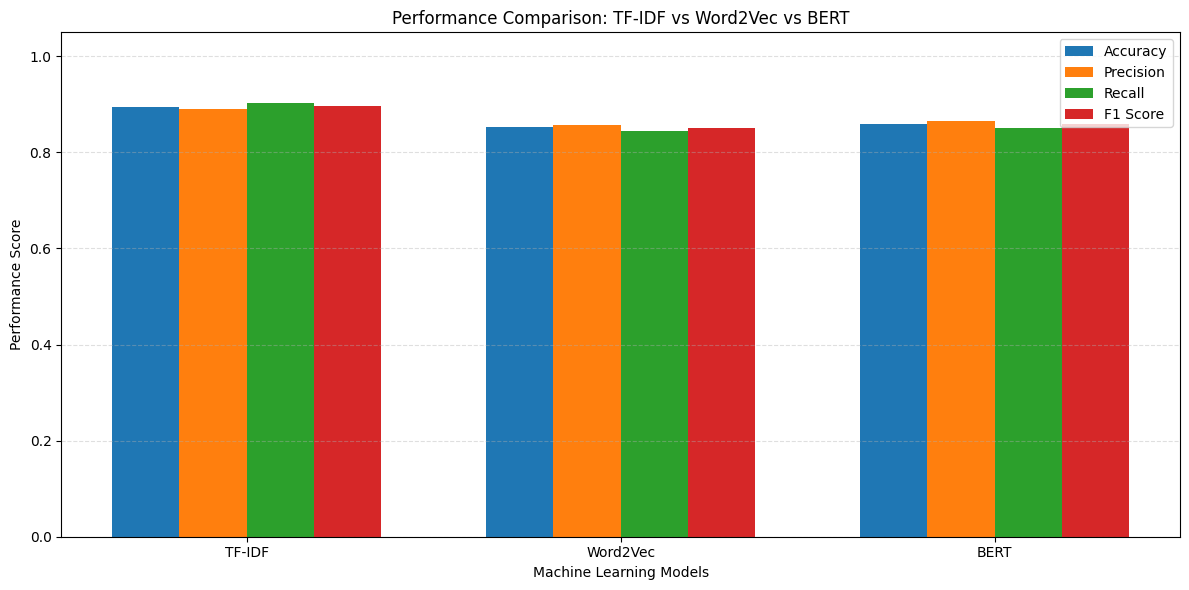

In [46]:

import matplotlib.pyplot as plt
import numpy as np

# Select evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

# Prepare chart data
models = comparison_df["Model"]

x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        comparison_df[metric],
        width,
        label=metric
    )

plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.title("Performance Comparison: TF-IDF vs Word2Vec vs BERT")

plt.xticks(x, models)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## **Error Analysis**

In [47]:

import numpy as np

# Find incorrect predictions for each model
tfidf_errors = np.where(
    tfidf_predictions != y_test
)[0]

w2v_errors = np.where(
    w2v_predictions != y_test
)[0]

bert_errors = np.where(
    bert_predictions != y_test
)[0]

print("ERROR ANALYSIS")
print("=" * 50)

print("TF-IDF incorrect predictions:", len(tfidf_errors))
print("Word2Vec incorrect predictions:", len(w2v_errors))
print("BERT incorrect predictions:", len(bert_errors))

# Display some BERT misclassified reviews
print("\nExamples of BERT Misclassified Reviews")

# Use the original test reviews
test_reviews = X_test_clean

for idx in bert_errors[:5]:

    print("\n" + "-" * 60)

    print("Review:", test_reviews[idx][:400])

    print(
        "Actual Sentiment:",
        "Positive" if y_test[idx] == 1 else "Negative"
    )

    print(
        "Predicted Sentiment:",
        "Positive" if bert_predictions[idx] == 1 else "Negative"
    )

print("\nCommon Sources of Classification Errors:")
print("1. Sarcasm and irony.")
print("2. Mixed positive and negative opinions.")
print("3. Negation and complex sentence structures.")
print("4. Long reviews containing multiple sentiments.")
print("5. Context-dependent expressions.")


ERROR ANALYSIS
TF-IDF incorrect predictions: 2616
Word2Vec incorrect predictions: 3690
BERT incorrect predictions: 3515

Examples of BERT Misclassified Reviews

------------------------------------------------------------
Review: first off let me say if you havent enjoyed a van damme movie since bloodsport you probably will not like this movie most of these movies may not have the best plots or best actors but i enjoy these kinds of movies for what they are this movie is much better than any of the movies the other action guys segal and dolph have thought about putting out the past few years van damme is good in the movie 
Actual Sentiment: Negative
Predicted Sentiment: Positive

------------------------------------------------------------
Review: isaac florentine has made some of the best western martial arts action movies ever produced in particular us seals 2 cold harvest special forces and undisputed 2 are all action classics you can tell isaac has a real passion for the genre and 

## **Final Conclusion**

## Conclusion and Observations

In this project, I performed sentiment analysis on the IMDB movie reviews dataset using three different text representation techniques: TF-IDF, Word2Vec, and BERT embeddings. The main objective was to compare the performance of these approaches in classifying movie reviews as positive or negative.

First, I performed data preprocessing, including converting text to lowercase, removing HTML tags, cleaning punctuation, and tokenizing reviews. The dataset was divided into training, validation, and testing sets to ensure reliable model evaluation. Logistic Regression was used as the classification algorithm for all three approaches.

The first method was TF-IDF (Term Frequency-Inverse Document Frequency). It converts text into numerical features based on the importance of words in a document. TF-IDF achieved the highest performance, with an accuracy of 89.54%, precision of 89.02%, recall of 90.19%, and an F1-score of 89.60%. This demonstrates that traditional text vectorization techniques can perform very effectively in sentiment classification.

The second method was Word2Vec. It represents words as dense numerical vectors and captures semantic relationships between words. Word2Vec achieved an accuracy of 85.24% and an F1-score of 85.13%. Although it captures similarities between words, averaging word embeddings can lose word order and contextual information, which may affect classification performance.

The third method was BERT embeddings using the pretrained DistilBERT model. BERT generates contextual representations by considering surrounding words. It achieved an accuracy of 85.94%, precision of 86.49%, recall of 85.18%, and an F1-score of 85.83%. Although BERT provides contextual information, it required more computational resources and processing time.

Based on the experimental results, TF-IDF performed better than both Word2Vec and BERT embeddings in this experiment. The recorded processing times were 3.16 seconds for TF-IDF, 0.25 seconds for Word2Vec, and 361.94 seconds for BERT. These times depend on the implementation and hardware, and the BERT time includes embedding extraction.

During error analysis, I observed that sarcasm, irony, mixed opinions, negation, and complex sentence structures can cause incorrect sentiment predictions.

In conclusion, the experiment demonstrates that the most advanced text representation method does not always produce the highest classification accuracy. TF-IDF provided the best overall classification performance in this experiment, while Word2Vec was computationally efficient and BERT offered contextual language representations. The choice of method should depend on classification performance, computational resources, and processing time.